**Eliott Rakotondramanitra · Louis-Antoine Pham**  
Research project · Parameter-Efficient Fine-Tuning

# Parameter-Efficient Fine-Tuning: Comparative Study

**LoRA · QLoRA · IA³ · Prompt Tuning · Full-model baseline**

## Research objective

This experimental study compares parameter-efficient adaptation techniques for sentiment classification on **IMDb**, using pretrained **DistilBERT** and **RoBERTa** classifiers. We examine the trade-off between **accuracy, trainable parameter count, model memory footprint, and training time**.

The notebook includes two complementary components:

1. **Method-level implementations:** manual LoRA and INT8 quantization to explore their mechanics, including a LoRA rank study.
2. **Comparative experiments:** adaptations using Hugging Face PEFT (LoRA, QLoRA, IA³, Prompt Tuning), followed by comparisons on DistilBERT and RoBERTa.

The pretrained classifiers serve as **reference baselines**; they should not be interpreted as a full fine-tuning experiment performed on IMDb unless such training is explicitly run. This is a research notebook, not a production training pipeline.

The accompanying report, *Experimental study of Parameter-Efficient Finetuning (PEFT)*, presents the results and discusses the benefits and limitations of these approaches.

## Experimental environment and dataset


### Libraries and compute device
The following cells initialize the dependencies and select an available accelerator.

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import math
import pandas as pd
import matplotlib.pyplot as plt
import evaluate
from typing import Tuple, List
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments,T5ForSequenceClassification
from datasets import load_dataset


2026-01-09 17:06:01.630429: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
def get_best_device():
    """Returns the best device on this computer"""

    if torch.cuda.is_available():
        device = torch.device("cuda")
        total_memory = torch.cuda.get_device_properties(device).total_memory
        print(f"GPU Memory: {total_memory / 1e9:.1f} GB")
        print(f"GPU Name: {torch.cuda.get_device_name(device)}")
    elif torch.backends.mps.is_available():
        
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
    print(f"Found device: {device}")
    return device


device = get_best_device()

GPU Memory: 6.4 GB
GPU Name: NVIDIA GeForce RTX 3060 Laptop GPU
Found device: cuda


### IMDb sentiment classification data
A subset of the IMDb dataset is used for the experiments to limit training costs.

In [4]:
print("Loading IMDb dataset...")
dataset = load_dataset("imdb", split="train")
dataset = dataset.map(lambda x: {"labels": x.pop("label")})

# Use a subset (for speed in efficiency experiments)
dataset = dataset.shuffle(seed=42)

# Default dataset configuration (can be modified for faster experimentation)
dataset_size = 10_000
eval_split = 0.05


dataset = dataset.select(range(dataset_size))

# Split into train/val
train_val = dataset.train_test_split(test_size=eval_split, seed=42)
train_dataset = train_val["train"]
eval_dataset = train_val["test"]

print(f"Train: {len(train_dataset)}, Eval: {len(eval_dataset)}")

Loading IMDb dataset...
Train: 9500, Eval: 500


### Pretrained baseline: DistilBERT
We start from a classifier pretrained and fine-tuned on SST-2, then evaluate or adapt it on IMDb.

In [5]:
print("Loading pre-trained sentiment classifier...")
classifier_model_name = "distilbert-base-uncased-finetuned-sst-2-english"
classifier_tokenizer = AutoTokenizer.from_pretrained(classifier_model_name)
classifier_model = AutoModelForSequenceClassification.from_pretrained(
    classifier_model_name
).to(device)

print(f"Model: {classifier_model_name}")
print(f"Parameters: {sum(p.numel() for p in classifier_model.parameters()):,}")

Loading pre-trained sentiment classifier...
Model: distilbert-base-uncased-finetuned-sst-2-english
Parameters: 66,955,010


### Dataset tokenization

In [6]:
print("Tokenizing datasets...")


def preprocess_function(examples):
    return classifier_tokenizer(
        examples["text"], truncation=True, max_length=256, padding="max_length"
    )


train_dataset = train_dataset.map(preprocess_function, batched=True)
eval_dataset = eval_dataset.map(preprocess_function, batched=True)

train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
eval_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

print(
    f"Datasets tokenized with {len(train_dataset[0]['input_ids'])} tokens per example"
)

Tokenizing datasets...
Datasets tokenized with 256 tokens per example


In [7]:
# Evaluate baseline accuracy on IMDB dataset
print("Evaluating baseline accuracy...")
classifier_model.eval()

# Compute baseline accuracy
accuracy_metric = evaluate.load("accuracy")


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = logits.argmax(axis=-1)
    return accuracy_metric.compute(predictions=predictions, references=labels)


training_args = TrainingArguments(
    output_dir="./trained-models/tmp",
    per_device_eval_batch_size=32,
    report_to="none",
)

trainer = Trainer(
    model=classifier_model,
    args=training_args,
    compute_metrics=compute_metrics,
)
prediction_output = trainer.predict(eval_dataset)

classifier_accuracy = compute_metrics(
    (prediction_output.predictions, prediction_output.label_ids)
)["accuracy"]

print(f"Baseline accuracy on IMDB: {classifier_accuracy:.4f}")

Evaluating baseline accuracy...


Baseline accuracy on IMDB: 0.8960


### Dataset overview and reference accuracy

In [8]:
print(f"Device: {device}")
print(f"Train samples: {len(train_dataset)}")
print(f"Test samples: {len(eval_dataset)}")
print(f"Model: {classifier_model_name}")
print(f"Baseline accuracy: {classifier_accuracy:.4f}")

Device: cuda
Train samples: 9500
Test samples: 500
Model: distilbert-base-uncased-finetuned-sst-2-english
Baseline accuracy: 0.8960


---
## 1. LoRA: manual implementation

**Low-Rank Adaptation (LoRA)** keeps the pretrained weight matrix $W$ frozen and learns a low-rank update $\Delta W = BA$, where the rank $r$ is substantially smaller than the matrix dimensions. This section explores a PyTorch implementation before using the PEFT library.

Reference: [Hu et al., LoRA (2021)](https://arxiv.org/abs/2106.09685).


### LoRA layer implementation

In [9]:
class LoRALayer(nn.Module):
    """
    LoRA (Low-Rank Adaptation) layer.

    Implements: output = W @ x + (B @ A) @ x * (alpha / r)
    where W is frozen, A and B are trainable.

    Args:
        original_layer: The linear layer to adapt
        r: Rank of adaptation matrices (default: 8)
        alpha: Scaling factor (default: 16, effective scale is alpha/r)
    """


    def __init__(self,
        original_layer: nn.Linear,
        r: int = 8,
        alpha: float = 16):

        super(LoRALayer, self).__init__()
        # Initialize LoRA matrices A and B


        self.A = nn.Linear(original_layer.in_features, r)
        self.B = nn.Linear(r, original_layer.out_features)

         # Freeze original layer

        for param in original_layer.parameters():
          param.requires_grad = False

        self.original_layer = original_layer
        self.alpha = alpha
        self.r = r

        # Initialize A with kaiming_uniform (standard init)
        nn.init.kaiming_uniform_(self.A.weight)
        # Initialize B with zeros (important: starts as identity)
        nn.init.zeros_(self.B.weight)


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Implement LoRA forward pass

        x_W = self.original_layer(x) # Compute original output
        x_A = self.A(x)
        x_B = self.B(x_A)
        return x_W + x_B * (self.alpha / self.r) # Compute LoRA adaptation: B @ A @ x, scaled by alpha/r



    def merge_weights(self):
        """Merge LoRA weights into original layer for deployment."""
        # Optional: Implement weight merging
        return self.original_layer.weight + self.B.weight @ self.A.weight  * (self.alpha / self.r)



### Inserting LoRA layers into DistilBERT attention

In [10]:
def apply_lora_to_distilbert(
    model: nn.Module,
    r: int = 8,
    alpha: float = 16,
    target_modules: List[str] = None,
) -> List[nn.Parameter]:
    """
    Apply LoRA to specific modules in DistilBERT.

    Args:
        model: DistilBERT model
        r: LoRA rank
        alpha: LoRA alpha
        target_modules: Which attention matrices to adapt (q_lin, k_lin, v_lin, out_lin)

    Returns:
        List of LoRA parameters to optimize
    """
    if target_modules is None:
        target_modules = ["q_lin", "v_lin"]

    lora_params = []

    # Iterate through transformer layers
    for i, layer in enumerate(model.distilbert.transformer.layer):
        attention = layer.attention

        for module_name in target_modules:
            if hasattr(attention, module_name):
                original_layer = getattr(attention, module_name)

                # Replace with LoRA layer
                lora_layer = LoRALayer(original_layer, r=r, alpha=alpha)
                setattr(attention, module_name, lora_layer)

                # Collect LoRA parameters
                lora_params.extend([lora_layer.A.weight, lora_layer.B.weight])

                print(f"Applied LoRA to layer {i} -> {module_name}")

    return lora_params


def count_trainable_parameters(model: nn.Module) -> Tuple[int, int]:
    """
    Count trainable vs total parameters.

    Returns:
        (trainable_params, total_params)
    """
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

In [11]:
# Load base model
lora_model = AutoModelForSequenceClassification.from_pretrained(
    classifier_model_name,
    num_labels=2,
).to(device)
# And look at its parameters
lora_model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSdpaAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


### Adaptation and training configuration

In [12]:
# Setup LoRA training
lora_model.train()
# Freeze ALL model parameters first
for params in lora_model.parameters():
  params.requires_grad = False

# Apply LoRA to attention layers (q_lin and v_lin)
apply_lora_to_distilbert(lora_model,target_modules = ["q_lin", "v_lin"])

# Count trainable parameters
trainable, total = count_trainable_parameters(lora_model)
print(f"Total parameters: {total:,}")
print(f"Trainable parameters: {trainable:,}")

lora_model


Applied LoRA to layer 0 -> q_lin
Applied LoRA to layer 0 -> v_lin
Applied LoRA to layer 1 -> q_lin
Applied LoRA to layer 1 -> v_lin
Applied LoRA to layer 2 -> q_lin
Applied LoRA to layer 2 -> v_lin
Applied LoRA to layer 3 -> q_lin
Applied LoRA to layer 3 -> v_lin
Applied LoRA to layer 4 -> q_lin
Applied LoRA to layer 4 -> v_lin
Applied LoRA to layer 5 -> q_lin
Applied LoRA to layer 5 -> v_lin
Total parameters: 67,111,778
Trainable parameters: 156,768


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSdpaAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): LoRALayer(
              (A): Linear(in_features=768, out_features=8, bias=True)
              (B): Linear(in_features=8, out_features=768, bias=True)
              (original_layer): Linear(in_features=768, out_features=768, bias=True)
            )
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): LoRALayer(
              (A): Linear(in_features=768, out_features=8, bias=True)
              (B): 

In [13]:
# Train LoRA model

# Default training configuration (can be reduced for faster experimentation)
num_epochs = 1
logging_steps = 100


print(f"\nTraining LoRA model ({num_epochs} epochs)...")

training_args = TrainingArguments(
    output_dir="./trained-models/lora-distillbert-imdb",
    num_train_epochs=num_epochs,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=logging_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

trainer.train()

# Evaluate
lora_results = trainer.evaluate()
print(f"\nLoRA model accuracy: {lora_results['eval_accuracy']:.4f}")


Training LoRA model (1 epochs)...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.367800,0.317131,0.860000



LoRA model accuracy: 0.8600


### Comparison with the pretrained baseline
The baseline shown here is a pretrained classifier, not a separately trained full-fine-tuning run on IMDb.

In [14]:
# Compare results
print("\n" + "=" * 80)
print("COMPARISON: LoRA vs Full Fine-tuning")
print("=" * 80)

# Full fine-tuning baseline (from distillbert_imdb.py)
baseline_accuracy = classifier_accuracy
print(f"Full fine-tuning: {baseline_accuracy:.4f} accuracy, 66M trainable params")
print(
    f"LoRA (r=8):       {lora_results['eval_accuracy']:.4f} accuracy, "
    f"{trainable:,} trainable params"
)
print(f"\nParameter reduction: {100*(1-trainable/66e6):.2f}%")
print(f"Accuracy drop: {100*(baseline_accuracy - lora_results['eval_accuracy']):.2f}%")


COMPARISON: LoRA vs Full Fine-tuning
Full fine-tuning: 0.8960 accuracy, 66M trainable params
LoRA (r=8):       0.8600 accuracy, 156,768 trainable params

Parameter reduction: 99.76%
Accuracy drop: 3.60%


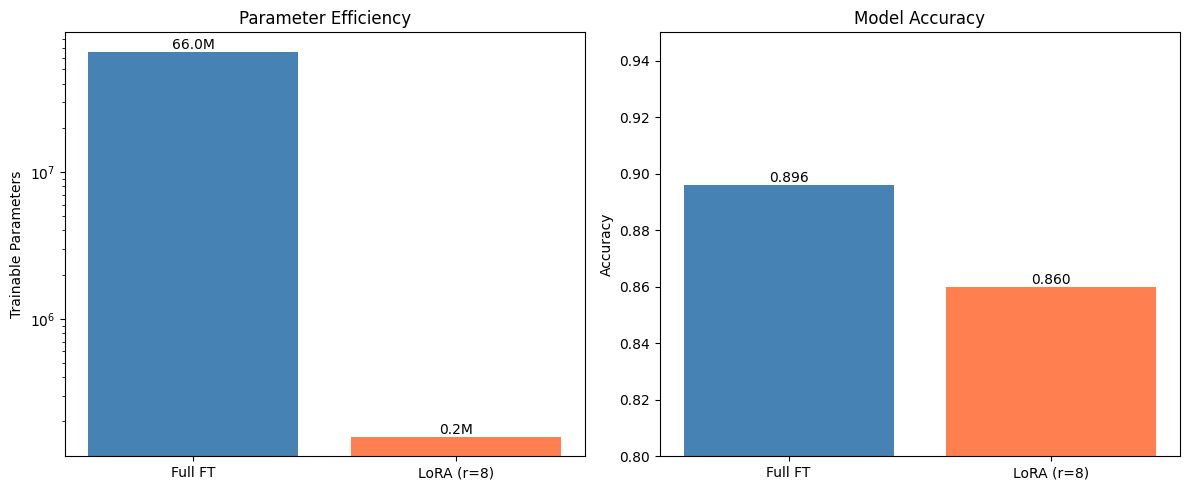

In [15]:
# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Parameters comparison
methods = ["Full FT", "LoRA (r=8)"]
params = [66e6, trainable]
colors = ["steelblue", "coral"]

ax1.bar(methods, params, color=colors)
ax1.set_ylabel("Trainable Parameters")
ax1.set_title("Parameter Efficiency")
ax1.set_yscale("log")
for i, (method, param) in enumerate(zip(methods, params)):
    ax1.text(i, param, f"{param/1e6:.1f}M", ha="center", va="bottom")

# Accuracy comparison
accuracies = [baseline_accuracy, lora_results["eval_accuracy"]]
ax2.bar(methods, accuracies, color=colors)
ax2.set_ylabel("Accuracy")
ax2.set_title("Model Accuracy")
ax2.set_ylim([0.80, 0.95])
for i, (method, acc) in enumerate(zip(methods, accuracies)):
    ax2.text(i, acc, f"{acc:.3f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

### Sensitivity analysis: LoRA rank
Evaluate how different adaptation ranks affect trainable parameters and task performance.

In [16]:
def train(model,args,train_dataset,eval_dataset):
    
    trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
    )
    trainer.train()
    
    lora_model.eval()
    lora_results = trainer.evaluate()
    
    return lora_results

Applied LoRA to layer 0 -> q_lin
Applied LoRA to layer 0 -> v_lin
Applied LoRA to layer 1 -> q_lin
Applied LoRA to layer 1 -> v_lin
Applied LoRA to layer 2 -> q_lin
Applied LoRA to layer 2 -> v_lin
Applied LoRA to layer 3 -> q_lin
Applied LoRA to layer 3 -> v_lin
Applied LoRA to layer 4 -> q_lin
Applied LoRA to layer 4 -> v_lin
Applied LoRA to layer 5 -> q_lin
Applied LoRA to layer 5 -> v_lin
Total parameters: 67,038,002
Trainable parameters: 82,992


Epoch,Training Loss,Validation Loss,Accuracy
1,0.646900,0.591220,0.710000


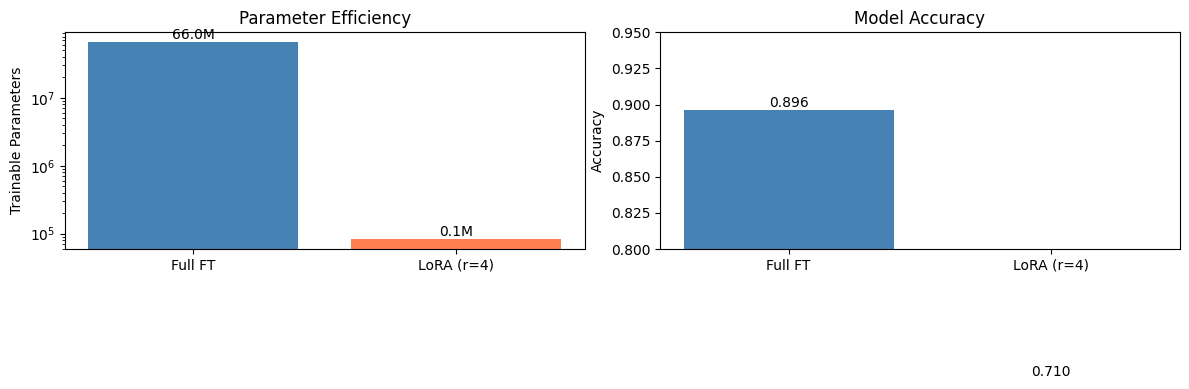

Applied LoRA to layer 0 -> q_lin
Applied LoRA to layer 0 -> v_lin
Applied LoRA to layer 1 -> q_lin
Applied LoRA to layer 1 -> v_lin
Applied LoRA to layer 2 -> q_lin
Applied LoRA to layer 2 -> v_lin
Applied LoRA to layer 3 -> q_lin
Applied LoRA to layer 3 -> v_lin
Applied LoRA to layer 4 -> q_lin
Applied LoRA to layer 4 -> v_lin
Applied LoRA to layer 5 -> q_lin
Applied LoRA to layer 5 -> v_lin
Total parameters: 67,074,890
Trainable parameters: 119,880


Epoch,Training Loss,Validation Loss,Accuracy
1,0.417800,0.303147,0.856000


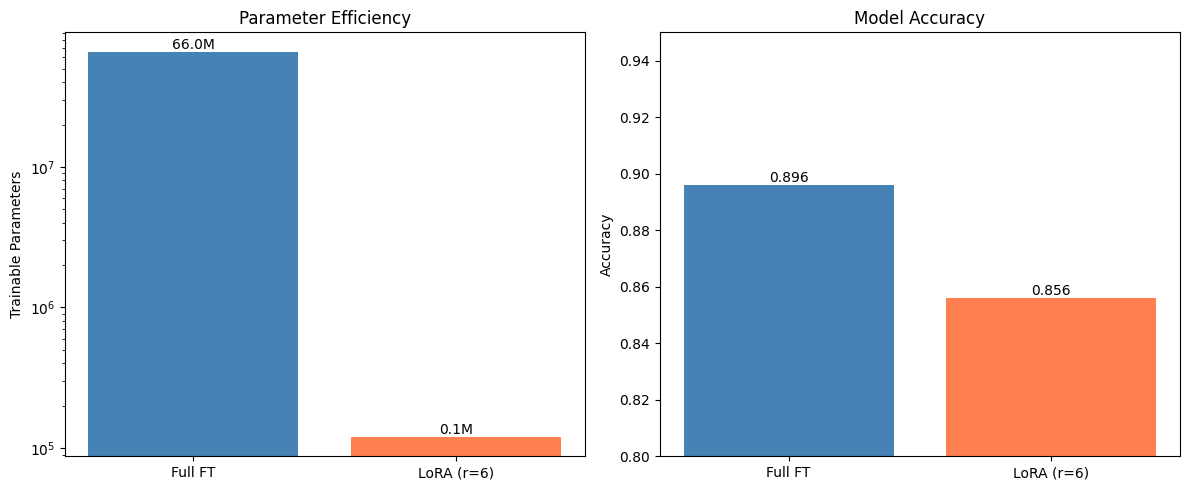

Applied LoRA to layer 0 -> q_lin
Applied LoRA to layer 0 -> v_lin
Applied LoRA to layer 1 -> q_lin
Applied LoRA to layer 1 -> v_lin
Applied LoRA to layer 2 -> q_lin
Applied LoRA to layer 2 -> v_lin
Applied LoRA to layer 3 -> q_lin
Applied LoRA to layer 3 -> v_lin
Applied LoRA to layer 4 -> q_lin
Applied LoRA to layer 4 -> v_lin
Applied LoRA to layer 5 -> q_lin
Applied LoRA to layer 5 -> v_lin
Total parameters: 67,111,778
Trainable parameters: 156,768


Epoch,Training Loss,Validation Loss,Accuracy
1,0.371400,0.261540,0.888000


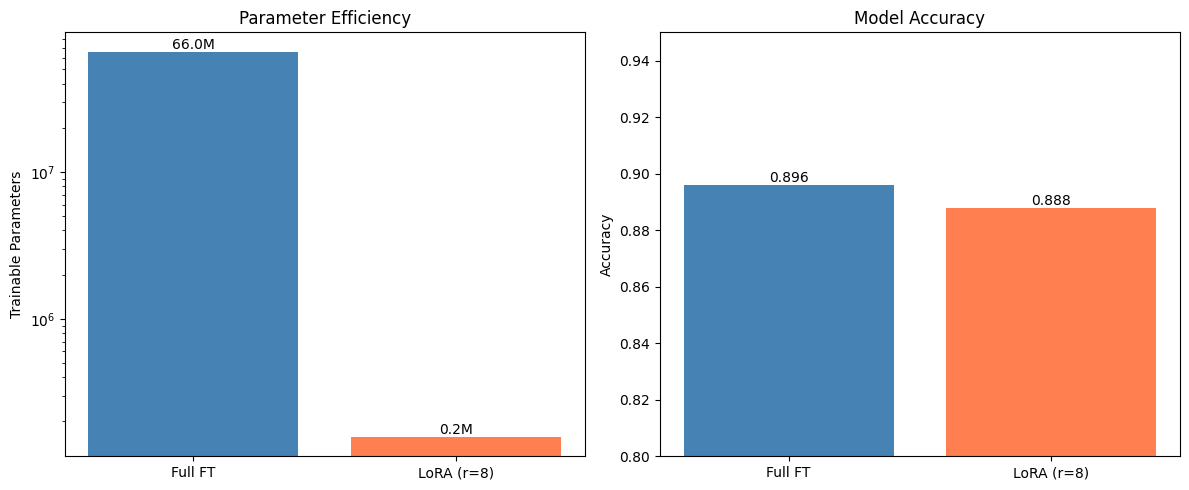

Applied LoRA to layer 0 -> q_lin
Applied LoRA to layer 0 -> v_lin
Applied LoRA to layer 1 -> q_lin
Applied LoRA to layer 1 -> v_lin
Applied LoRA to layer 2 -> q_lin
Applied LoRA to layer 2 -> v_lin
Applied LoRA to layer 3 -> q_lin
Applied LoRA to layer 3 -> v_lin
Applied LoRA to layer 4 -> q_lin
Applied LoRA to layer 4 -> v_lin
Applied LoRA to layer 5 -> q_lin
Applied LoRA to layer 5 -> v_lin
Total parameters: 67,185,554
Trainable parameters: 230,544


Epoch,Training Loss,Validation Loss,Accuracy
1,0.353300,0.266990,0.884000


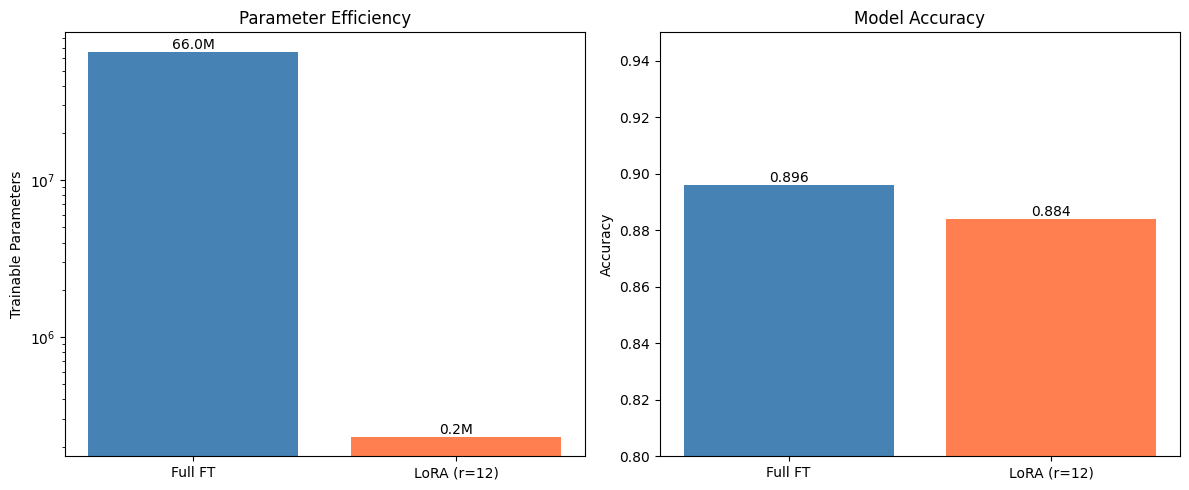

Applied LoRA to layer 0 -> q_lin
Applied LoRA to layer 0 -> v_lin
Applied LoRA to layer 1 -> q_lin
Applied LoRA to layer 1 -> v_lin
Applied LoRA to layer 2 -> q_lin
Applied LoRA to layer 2 -> v_lin
Applied LoRA to layer 3 -> q_lin
Applied LoRA to layer 3 -> v_lin
Applied LoRA to layer 4 -> q_lin
Applied LoRA to layer 4 -> v_lin
Applied LoRA to layer 5 -> q_lin
Applied LoRA to layer 5 -> v_lin
Total parameters: 67,259,330
Trainable parameters: 304,320


Epoch,Training Loss,Validation Loss,Accuracy
1,0.418500,0.276995,0.908000


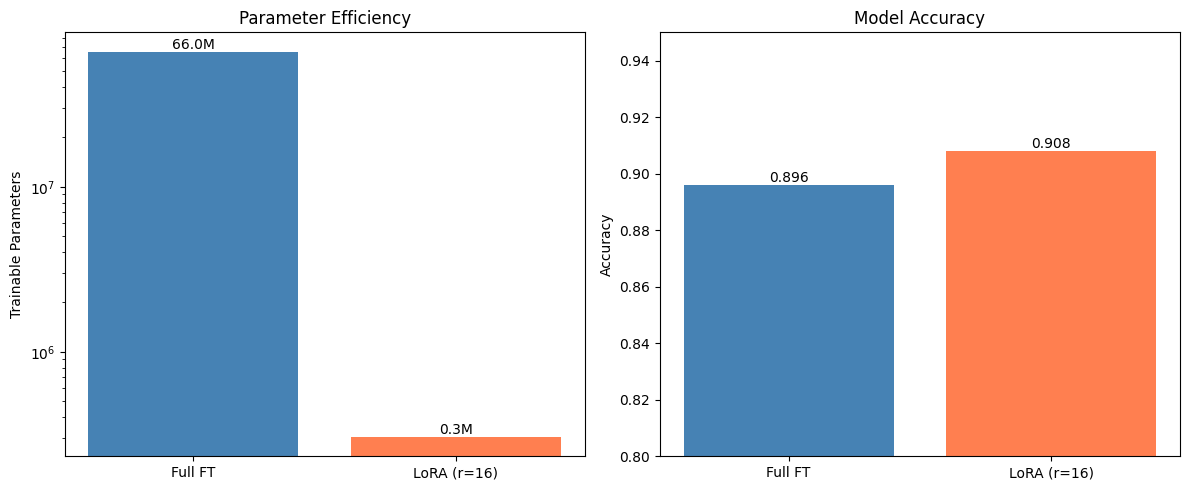

[0.71, 0.856, 0.888, 0.884, 0.908]


In [18]:
# Experiment with different ranks
eval = []

for r in [4,6,8,12,16]:

    lora_model = AutoModelForSequenceClassification.from_pretrained(
    classifier_model_name,
    num_labels=2,
    ).to(device)
    # Apply LoRA
    lora_model.train()

    # Freeze ALL model parameters first
    for param in lora_model.parameters():
        param.requires_grad = False
    # Apply LoRA to attention layers (q_lin and v_lin)
    apply_lora_to_distilbert(lora_model,r=r,target_modules = ["q_lin", "v_lin"])

    # Count params
    trainable, total = count_trainable_parameters(lora_model)
    print(f"Total parameters: {total:,}")
    print(f"Trainable parameters: {trainable:,}")

    # Train (1 epoch for speed)
    lora_results = train(lora_model,training_args,train_dataset,eval_dataset)
    # Evaluate
    eval.append(lora_results["eval_accuracy"])

    # Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    current_r = f"LoRA (r={r})"
    methods = ["Full FT", current_r]
    params = [66e6, trainable]
    colors = ["steelblue", "coral"]

    ax1.bar(methods, params, color=colors)
    ax1.set_ylabel("Trainable Parameters")
    ax1.set_title("Parameter Efficiency")
    ax1.set_yscale("log")
    for i, (method, param) in enumerate(zip(methods, params)):
        ax1.text(i, param, f"{param/1e6:.1f}M", ha="center", va="bottom")


    accuracies = [baseline_accuracy, lora_results["eval_accuracy"]]
    ax2.bar(methods, accuracies, color=colors)
    ax2.set_ylabel("Accuracy")
    ax2.set_title("Model Accuracy")
    ax2.set_ylim([0.80, 0.95])
    for i, (method, acc) in enumerate(zip(methods, accuracies)):
        ax2.text(i, acc, f"{acc:.3f}", ha="center", va="bottom")

    plt.tight_layout()
    plt.show()

# Plot results
print(eval)


---
## 2. INT8 quantization: manual implementation

We explore **post-training symmetric INT8 quantization** of selected DistilBERT feed-forward layers and measure the effect on memory use and classification accuracy.

For tensor values $x$, the scale is $s = \max(|x|)/127$, with $q = \mathrm{round}(x/s)$ and approximate reconstruction $\hat{x} = q s$.

This experiment is distinct from **QLoRA**, which uses a quantized base model with trainable LoRA adapters.


### Quantization and dequantization functions

In [31]:
def quantize_tensor(
    tensor: torch.Tensor,
    bits: int = 8,
) -> Tuple[torch.Tensor, float]:
    """
    Quantize tensor to INT8 using symmetric quantization.

    Args:
        tensor: FP32 tensor to quantize
        bits: Number of bits (default: 8)

    Returns:
        quantized: INT8 tensor
        scale: Scale factor for dequantization
    """
    # Implement symmetric INT8 quantization

    # Compute scale factor

    scale = torch.max(torch.absolute(tensor))/127

    # Quantize: divide by scale, round, clamp to INT8 range

    quantized_tensor = torch.round(tensor / scale)
    quantized_tensor = torch.clamp(quantized_tensor, -127, 127)

    return (quantized_tensor.to(torch.int8),scale)


def dequantize_tensor(
    quantized: torch.Tensor,
    scale: float,
) -> torch.Tensor:
    """
    Dequantize INT8 tensor back to FP32.

    Args:
        quantized: INT8 tensor
        scale: Scale factor from quantization

    Returns:
        dequantized: FP32 tensor
    """
    # Implement dequantization
    dequantized = quantized.to(torch.float32)

    return (dequantized * scale)


### Quantization error on a sample tensor

In [32]:
# Test quantization
test_tensor = torch.randn(1000, 768)
print(f"Original tensor: shape={test_tensor.shape}, dtype={test_tensor.dtype}")
print(f"Original range: [{test_tensor.min():.4f}, {test_tensor.max():.4f}]")
print(f"Original memory: {test_tensor.nbytes / 1e6:.2f} MB")

# Quantize
quantized, scale = quantize_tensor(test_tensor)
print(f"\nQuantized tensor: shape={quantized.shape}, dtype={quantized.dtype}")
print(f"Quantized range: [{quantized.min()}, {quantized.max()}]")
print(f"Quantized memory: {quantized.nbytes / 1e6:.2f} MB")
print(f"Scale factor: {scale:.6f}")
print(f"Memory reduction: {test_tensor.nbytes / quantized.nbytes:.1f}x")

# Dequantize
dequantized = dequantize_tensor(quantized, scale)
print(f"\nDequantized tensor: shape={dequantized.shape}, dtype={dequantized.dtype}")
print(f"Dequantized range: [{dequantized.min():.4f}, {dequantized.max():.4f}]")

# Measure error
mse = ((test_tensor - dequantized) ** 2).mean()
print(f"\nReconstruction MSE: {mse:.6f}")
print(f"Relative error: {(mse / test_tensor.var()).sqrt():.4f}")

Original tensor: shape=torch.Size([1000, 768]), dtype=torch.float32
Original range: [-5.0201, 4.8302]
Original memory: 3.07 MB

Quantized tensor: shape=torch.Size([1000, 768]), dtype=torch.int8
Quantized range: [-127, 122]
Quantized memory: 0.77 MB
Scale factor: 0.039529
Memory reduction: 4.0x

Dequantized tensor: shape=torch.Size([1000, 768]), dtype=torch.float32
Dequantized range: [-5.0201, 4.8225]

Reconstruction MSE: 0.000130
Relative error: 0.0114


### Distribution of quantization errors

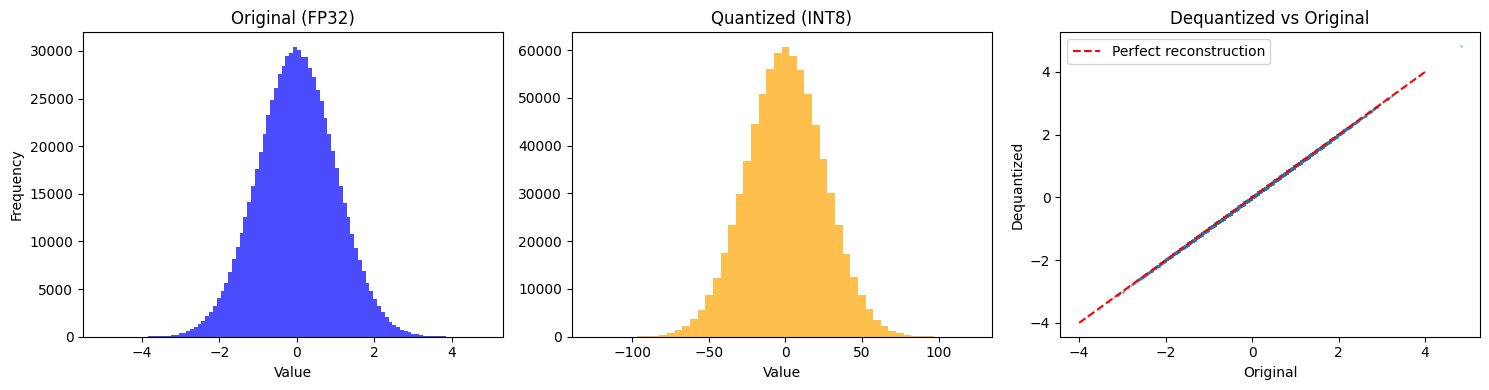

In [33]:
# Visualize weight distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Original
axes[0].hist(test_tensor.flatten().numpy(), bins=100, alpha=0.7, color="blue")
axes[0].set_title("Original (FP32)")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Frequency")

# Quantized
axes[1].hist(quantized.flatten().numpy(), bins=50, alpha=0.7, color="orange")
axes[1].set_title("Quantized (INT8)")
axes[1].set_xlabel("Value")

# Dequantized vs Original
axes[2].scatter(
    test_tensor.flatten().numpy()[::100],
    dequantized.flatten().numpy()[::100],
    alpha=0.3,
    s=1,
)
axes[2].plot([-4, 4], [-4, 4], "r--", label="Perfect reconstruction")
axes[2].set_title("Dequantized vs Original")
axes[2].set_xlabel("Original")
axes[2].set_ylabel("Dequantized")
axes[2].legend()

plt.tight_layout()
plt.show()

### INT8 linear layer implementation

In [34]:
class QuantizedLinear(nn.Module):
    """
    Quantized linear layer for FFN.

    Stores weights in INT8, dequantizes during forward pass.
    This is post-training quantization (PTQ).
    """

    def __init__(self, linear: nn.Linear):
        super().__init__()
        # Initialize quantized linear layer

        # Quantize weight matrix
        weight_quantized,scale = quantize_tensor(linear.weight)
        # Store as buffer (not parameter - don't train)
        self.register_buffer("weight_quantized",weight_quantized)
        self.register_buffer("scale",scale)
        # Keep bias as float (small, not worth quantizing)
        if linear.bias is not None:
            self.register_buffer("bias", linear.bias.clone())
        else:
            self.bias = None



    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Forward pass with dequantization

        # Dequantize weights on the fly
        with torch.no_grad():
            weight_deq = dequantize_tensor(self.weight_quantized,self.scale)
        # Apply linear transformation
        x = F.linear(x,weight_deq,self.bias)
        return x

    def get_memory_size(self) -> float:
        """Returns memory size in MB."""
        size = self.weight_quantized.nbytes  # INT8 weights
        if self.bias is not None:
            size += self.bias.nbytes
        return size / 1e6

### Quantization of DistilBERT feed-forward layers

In [35]:
# Load base model
model = AutoModelForSequenceClassification.from_pretrained(
    classifier_model_name,
    num_labels=2,
).to(device)

In [22]:
def quantize_distilbert_ffn(model: nn.Module) -> nn.Module:
    """
    Quantize all FFN layers (lin1, lin2) in DistilBERT.

    Args:
        model: DistilBERT model

    Returns:
        Model with quantized FFN layers
    """
    for i, layer in enumerate(model.distilbert.transformer.layer):
        ffn = layer.ffn

        # Quantize lin1 (768 -> 3072)
        ffn.lin1 = QuantizedLinear(ffn.lin1)

        # Quantize lin2 (3072 -> 768)
        ffn.lin2 = QuantizedLinear(ffn.lin2)

        print(f"Quantized layer {i} FFN (lin1, lin2)")

    return model


def measure_model_size(model: nn.Module) -> float:
    """
    Measure model size in MB.

    Returns:
        Size in MB
    """
    size = 0
    for param in model.parameters():
        size += param.numel() * param.element_size()
    for buffer in model.buffers():
        size += buffer.numel() * buffer.element_size()
    return size / 1e6

### Accuracy and memory comparison after quantization

In [37]:
# Quantize model and analyze results

# Measure original size
size_before = measure_model_size(model)
# Quantize FFN layers
quantized_model = quantize_distilbert_ffn(model)

# Measure quantized size
size_after = measure_model_size(quantized_model)

# Evaluate accuracy
quantized_model.eval()

from transformers import Trainer

trainer_quant = Trainer(
    model=quantized_model,
    args=TrainingArguments(output_dir="./trained-models/tmp", report_to="none"),
    compute_metrics=compute_metrics,
)
prediction_output = trainer_quant.predict(eval_dataset)
quantized_accuracy = compute_metrics(
    (prediction_output.predictions, prediction_output.label_ids)
)["accuracy"]

print(f"\nOriginal accuracy: {baseline_accuracy:.4f}")
print(f"Quantized accuracy: {quantized_accuracy:.4f}")
print(f"Accuracy drop: {100*(baseline_accuracy - quantized_accuracy):.2f}%")

Quantized layer 0 FFN (lin1, lin2)
Quantized layer 1 FFN (lin1, lin2)
Quantized layer 2 FFN (lin1, lin2)
Quantized layer 3 FFN (lin1, lin2)
Quantized layer 4 FFN (lin1, lin2)
Quantized layer 5 FFN (lin1, lin2)



Original accuracy: 0.8960
Quantized accuracy: 0.9000
Accuracy drop: -0.40%


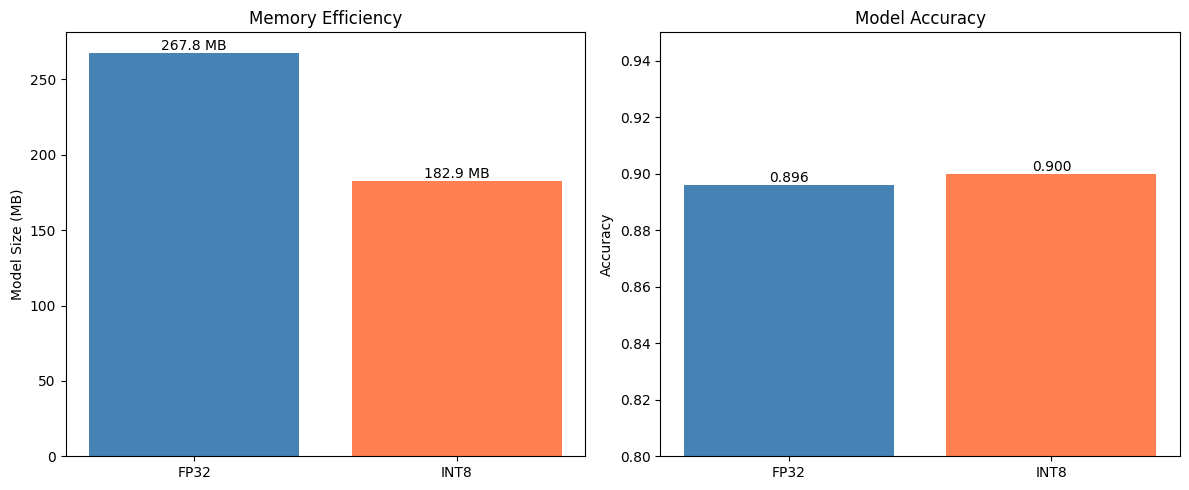

In [38]:
# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Memory comparison
methods = ["FP32", "INT8"]
sizes = [size_before, size_after]
colors = ["steelblue", "coral"]

ax1.bar(methods, sizes, color=colors)
ax1.set_ylabel("Model Size (MB)")
ax1.set_title("Memory Efficiency")
for i, (method, size) in enumerate(zip(methods, sizes)):
    ax1.text(i, size, f"{size:.1f} MB", ha="center", va="bottom")

# Accuracy comparison
accuracies = [baseline_accuracy, quantized_accuracy]
ax2.bar(methods, accuracies, color=colors)
ax2.set_ylabel("Accuracy")
ax2.set_title("Model Accuracy")
ax2.set_ylim([0.80, 0.95])
for i, (method, acc) in enumerate(zip(methods, accuracies)):
    ax2.text(i, acc, f"{acc:.3f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

---
## 3. PEFT methods on DistilBERT

The [Hugging Face PEFT library](https://huggingface.co/docs/peft) is used to compare **LoRA, IA³, Prompt Tuning and QLoRA** on the same IMDb sentiment-classification task.

The benchmark examines training efficiency, parameter count, model size and accuracy. GPU and quantization-library compatibility can affect which configurations are executable.


In [10]:

import time
from peft import (
    LoraConfig,
    IA3Config,
    PromptTuningConfig,PromptTuningInit,
    get_peft_model,
    PeftModel,
)

from peft import LoraConfig, get_peft_model, TaskType,prepare_model_for_kbit_training

### LoRA: PEFT implementation

In [40]:
num_epochs = 1
logging_steps = 100


In [41]:
# Configure LoRA using PEFT library
# Configure LoRA
# Load fresh base model
classifier_model = AutoModelForSequenceClassification.from_pretrained(classifier_model_name, num_labels=2).to(device)
peft_config = LoraConfig(task_type=TaskType.SEQ_CLS,target_modules = ["q_lin", "v_lin"], inference_mode=False, r=16, lora_alpha=32, lora_dropout=0.1)
peft_lora_model = get_peft_model(classifier_model, peft_config)

# Train PEFT LoRA model
training_args_peft = TrainingArguments(
    output_dir="./trained-models/peft-lora-distillbert-imdb",
    num_train_epochs=num_epochs,  # Use same config as manual LoRA
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=logging_steps,  # Use same config as manual LoRA
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer_peft = Trainer(
    model=peft_lora_model,
    args=training_args_peft,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

start_train = time.time()
trainer_peft.train()
end_train = time.time()

total_train_time_lora = end_train - start_train
time_per_epoch_lora = total_train_time_lora / training_args_peft.num_train_epochs

# Evaluate 
peft_lora_results = trainer_peft.evaluate()

# Display results

print(f"Total Training Time: {total_train_time_lora:.2f} seconds")
print(f"Training Time per Epoch: {time_per_epoch_lora:.2f} seconds")
print(f"PEFT LoRA accuracy: {peft_lora_results['eval_accuracy']:.4f}")

Epoch,Training Loss,Validation Loss,Accuracy
1,0.310300,0.248458,0.904000


Total Training Time: 111.76 seconds
Training Time per Epoch: 111.76 seconds
PEFT LoRA accuracy: 0.9040


### Additional adaptation methods

#### IA³: learned activation rescaling

In [42]:
classifier_model = AutoModelForSequenceClassification.from_pretrained(classifier_model_name, num_labels=2).to(device)

# Apply PEFT
ia3_config = IA3Config(
    task_type=TaskType.SEQ_CLS,
    target_modules=["q_lin", "v_lin","lin1","lin2"],
    feedforward_modules=["lin1", "lin2"]
)

peft_ia3_model = get_peft_model(classifier_model, ia3_config)


# Train PEFT IA3 model
training_args_peft = TrainingArguments(
    output_dir="./trained-models/peft-ia3-distillbert-imdb",
    num_train_epochs=num_epochs,  # Use same config as manual LoRA
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=logging_steps,  # Use same config as manual LoRA
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer_peft = Trainer(
    model=peft_ia3_model,
    args=training_args_peft,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

start_train = time.time()
trainer_peft.train()
end_train = time.time()

total_train_time_ia3 = end_train - start_train
time_per_epoch_ia3 = total_train_time_ia3 / training_args_peft.num_train_epochs

# Evaluate
peft_ia3_results = trainer_peft.evaluate()

# Display results
print(f"Total Training Time: {total_train_time_ia3:.2f} seconds")
print(f"Training Time per Epoch: {time_per_epoch_ia3:.2f} seconds") 
print(f"PEFT IA3 accuracy: {peft_ia3_results['eval_accuracy']:.4f}")



Epoch,Training Loss,Validation Loss,Accuracy
1,0.314200,0.252552,0.904000


Total Training Time: 116.25 seconds
Training Time per Epoch: 116.25 seconds
PEFT IA3 accuracy: 0.9040


#### Prompt Tuning: learned soft prompt embeddings

In [43]:
classifier_model = AutoModelForSequenceClassification.from_pretrained(classifier_model_name, num_labels=2).to(device)
# Apply PEFT

prompt_tuning_config = PromptTuningConfig(
    task_type=TaskType.SEQ_CLS,
    num_virtual_tokens=20,
    prompt_tuning_init=PromptTuningInit.TEXT,
    prompt_tuning_init_text="Classify if this movie review is positive or negative",
    num_layers=6,
    token_dim =classifier_model.distilbert.config.dim,
    num_attention_heads=classifier_model.distilbert.config.num_attention_heads,
    tokenizer_name_or_path=classifier_model_name,
)

peft_prompt_model = get_peft_model(classifier_model, prompt_tuning_config)

# Train PEFT Prompt Tuning model
training_args_peft = TrainingArguments(
    output_dir="./trained-models/peft-promptTuning-distillbert-imdb",
    num_train_epochs=num_epochs,  # Use same config as manual LoRA
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=logging_steps,  # Use same config as manual LoRA
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer_peft = Trainer(
    model=peft_prompt_model,
    args=training_args_peft,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

start_train = time.time()
trainer_peft.train()
end_train = time.time()

total_train_time_prompt = end_train - start_train
time_per_epoch_prompt = total_train_time_prompt / training_args_peft.num_train_epochs

# Evaluate
peft_promptTuning_results = trainer_peft.evaluate()

# Display results
print(f"Total Training Time: {total_train_time_prompt:.2f} seconds")
print(f"Training Time per Epoch: {time_per_epoch_prompt:.2f} seconds")
print(f"PEFT Prompt Tuning accuracy: {peft_promptTuning_results['eval_accuracy']:.4f}")

Epoch,Training Loss,Validation Loss,Accuracy
1,0.323900,0.273694,0.880000


Total Training Time: 111.81 seconds
Training Time per Epoch: 111.81 seconds
PEFT Prompt Tuning accuracy: 0.8800


#### QLoRA: quantized base model with LoRA adapters

In [44]:
from transformers import BitsAndBytesConfig

config = BitsAndBytesConfig(
   load_in_4bit=True,
   bnb_4bit_quant_type="nf4",
   bnb_4bit_use_double_quant=True,
   bnb_4bit_compute_dtype= torch.bfloat16,
   llm_int8_skip_modules=["classifier", "pre_classifier"]
)

model = AutoModelForSequenceClassification.from_pretrained(classifier_model_name, quantization_config = config,num_labels=2)
model_quantized = prepare_model_for_kbit_training(model)

peft_lora_config = LoraConfig(task_type=TaskType.SEQ_CLS,target_modules = ["q_lin", "v_lin"], inference_mode=False, r=16, lora_alpha=32, lora_dropout=0.1)
peft_Qlora_model = get_peft_model(model_quantized, peft_lora_config)

# Train PEFT QLoRA model
training_args_peft = TrainingArguments(
    output_dir="./trained-models/peft-qlora-distillbert-imdb",
    num_train_epochs=num_epochs,  # Use same config as manual LoRA
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=logging_steps,  # Use same config as manual LoRA
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer_peft = Trainer(
    model=peft_Qlora_model,
    args=training_args_peft,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

start_train = time.time()
trainer_peft.train()
end_train = time.time()
total_train_time_Qlora = end_train - start_train
time_per_epoch_Qlora = total_train_time_Qlora / training_args_peft.num_train_epochs

# Evaluate
peft_Qlora_results = trainer_peft.evaluate()

# Display results
print(f"Total Training Time: {total_train_time_Qlora:.2f} seconds")
print(f"Training Time per Epoch: {time_per_epoch_Qlora:.2f} seconds")
print(f"PEFT QLoRA accuracy: {peft_Qlora_results['eval_accuracy']:.4f}")


/home/louis-antoine/deepdac/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:838: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.314600,0.249663,0.898000


Total Training Time: 113.78 seconds
Training Time per Epoch: 113.78 seconds
PEFT QLoRA accuracy: 0.8980


### DistilBERT comparison: metrics and parameter counts

In [45]:
trainable_lora, _ = count_trainable_parameters(peft_lora_model)
trainable_ia3, _ = count_trainable_parameters(peft_ia3_model)
trainable_prompt, _ = count_trainable_parameters(peft_prompt_model)
trainable_Qlora, _ = count_trainable_parameters(peft_Qlora_model)

model_size_FULL =  measure_model_size(classifier_model)
model_size_lora =  measure_model_size(peft_lora_model)
model_size_ia3 =  measure_model_size(peft_ia3_model)
model_size_prompt =  measure_model_size(peft_prompt_model)
model_size_Qlora =  measure_model_size(peft_Qlora_model)


data = [
    {
        "Method": "Full FT",
        "Trainable Params": 66955010,
        "Accuracy": baseline_accuracy,
        "Model Size (MB)": model_size_FULL,
        "Time per Epoch": None
    },
    {
        "Method": "PEFT LoRA",
        "Trainable Params": trainable_lora,
        "Accuracy": peft_lora_results['eval_accuracy'],
        "Model Size (MB)": model_size_lora,
        "Time per Epoch": time_per_epoch_lora
    },
    {
        "Method": "PEFT IA3",
        "Trainable Params": trainable_ia3,
        "Accuracy": peft_ia3_results['eval_accuracy'],
        "Model Size (MB)": model_size_ia3,
        "Time per Epoch": time_per_epoch_ia3
    }
    ,
    {
        "Method": "PEFT Prompt Tuning",
        "Trainable Params": trainable_prompt,
        "Accuracy": peft_promptTuning_results['eval_accuracy'],
        "Model Size (MB)": model_size_prompt,
        "Time per Epoch": time_per_epoch_prompt
    },
    {
        "Method": "PEFT QLoRA",
        "Trainable Params": trainable_Qlora,
        "Accuracy": peft_Qlora_results['eval_accuracy'],
        "Model Size (MB)": model_size_Qlora,
        "Time per Epoch": time_per_epoch_Qlora
    }
]

df_peft = pd.DataFrame(data)

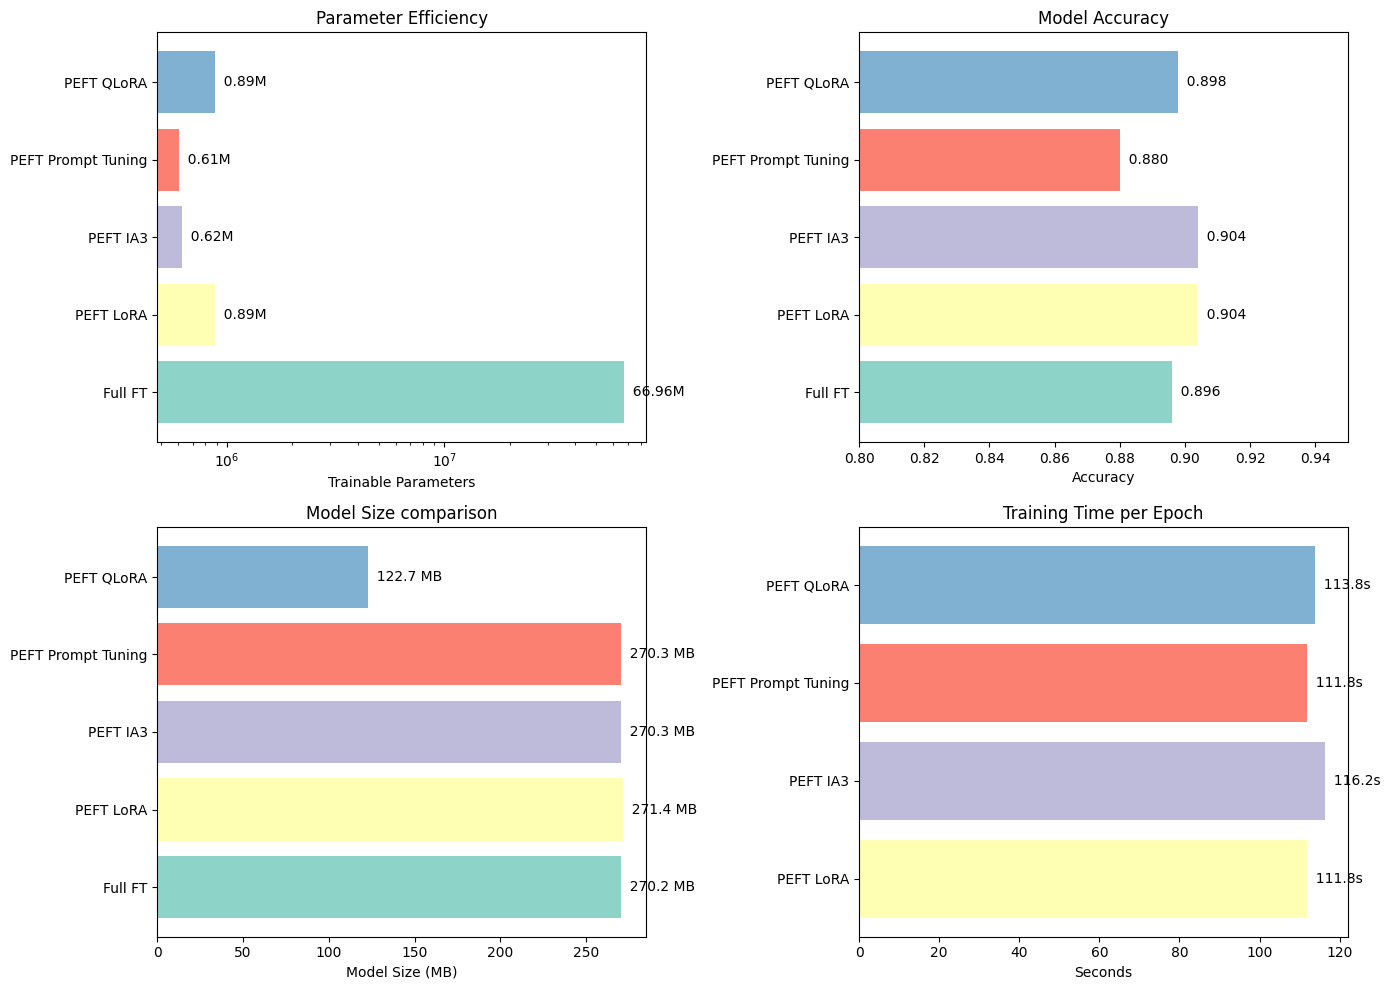

In [46]:
# Visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

# Trainable parameters
methods = df_peft["Method"].tolist()
params = df_peft["Trainable Params"].tolist()
colors = plt.cm.Set3(range(len(methods)))

ax1.barh(methods, params, color=colors)
ax1.set_xlabel("Trainable Parameters")
ax1.set_title("Parameter Efficiency")
ax1.set_xscale("log")
for i, (method, param) in enumerate(zip(methods, params)):
    ax1.text(param, i, f"  {param/1e6:.2f}M", va="center")

# Accuracy
accuracies = df_peft["Accuracy"].tolist()
ax2.barh(methods, accuracies, color=colors)
ax2.set_xlabel("Accuracy")
ax2.set_title("Model Accuracy")
ax2.set_xlim([0.80, 0.95])
for i, (method, acc) in enumerate(zip(methods, accuracies)):
    ax2.text(acc, i, f"  {acc:.3f}", va="center")

# Model Size
model_sizes = df_peft["Model Size (MB)"].tolist()
ax3.barh(methods, model_sizes, color=colors)
ax3.set_xlabel("Model Size (MB)")
ax3.set_title("Model Size comparison")
for i, size in enumerate(model_sizes):
    ax3.text(size, i, f"  {size:.1f} MB", va="center") 

# Time per Epoch
times = df_peft["Time per Epoch"].tolist() 
ax4.barh(methods, times, color=colors)
ax4.set_xlabel("Seconds")
ax4.set_title("Training Time per Epoch")
for i, t in enumerate(times):
    if t and not pd.isna(t):
        ax4.text(t, i, f"  {t:.1f}s", va="center")

plt.tight_layout()
plt.show()

### Saving, loading and evaluating LoRA adapters

In [47]:
# Save and load PEFT adapter

# Save adapter (only the adapter weights, not the base model)

adapter_path = "./trained-models/peft-lora-final-adapter"
peft_lora_model.save_pretrained(adapter_path)
# Load adapter back
base_model_fresh = AutoModelForSequenceClassification.from_pretrained(
    classifier_model_name, 
    num_labels=2
)

peft_loaded_model_lora = PeftModel.from_pretrained(base_model_fresh, adapter_path).to(device)


In [48]:
peft_loaded_model_lora.eval()

trainer_loaded = Trainer(
    model=peft_loaded_model_lora,
    args=TrainingArguments(output_dir="./trained-models/tmp", report_to="none"),
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

peft_loaded_results = trainer_loaded.evaluate()
print(f"Loaded PEFT LoRA adapter accuracy: {peft_loaded_results['eval_accuracy']:.4f}")

Loaded PEFT LoRA adapter accuracy: 0.9040


---
## 4. Comparative benchmark

The following experiments compare PEFT configurations on **DistilBERT** and **RoBERTa**. The analysis in the accompanying report focuses on **accuracy, trainable parameters, model size, and training time per epoch**.

**Key finding reported:** QLoRA offered a favorable accuracy–memory trade-off on the tested models. Results are context-dependent and are not independently reproduced by this documentation edit.


### Additional quantized-LoRA experiment
An additional implementation combining manual quantization and LoRA is explored here.

In [49]:
model = AutoModelForSequenceClassification.from_pretrained(
    classifier_model_name, 
    num_labels=2
)

model_quantized = quantize_distilbert_ffn(model).to(device)

for param in model_quantized.parameters():
    param.requires_grad = False

apply_lora_to_distilbert(model_quantized,r=16,target_modules = ["q_lin", "v_lin"])

# train

training_args_quant_lora = TrainingArguments(
    output_dir="./trained-models/quantized-lora-distillbert-imdb",
    num_train_epochs=1,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer_quant_lora = Trainer(
    model=model_quantized,
    args=training_args_quant_lora,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

# Train

start_train = time.time()
trainer_quant_lora.train()
end_train = time.time()
total_train_time_quant_lora = end_train - start_train
time_per_epoch_quant_lora = total_train_time_quant_lora / training_args_quant_lora.num_train_epochs

# Evaluate
QloraScratch_results = trainer_quant_lora.evaluate()

# Display results
print(f"Total Training Time: {total_train_time_quant_lora:.2f} seconds")
print(f"Training Time per Epoch: {time_per_epoch_quant_lora:.2f} seconds")
print(f"Quantized + LoRA accuracy: {QloraScratch_results['eval_accuracy']:.4f}")



Quantized layer 0 FFN (lin1, lin2)
Quantized layer 1 FFN (lin1, lin2)
Quantized layer 2 FFN (lin1, lin2)
Quantized layer 3 FFN (lin1, lin2)
Quantized layer 4 FFN (lin1, lin2)
Quantized layer 5 FFN (lin1, lin2)
Applied LoRA to layer 0 -> q_lin
Applied LoRA to layer 0 -> v_lin
Applied LoRA to layer 1 -> q_lin
Applied LoRA to layer 1 -> v_lin
Applied LoRA to layer 2 -> q_lin
Applied LoRA to layer 2 -> v_lin
Applied LoRA to layer 3 -> q_lin
Applied LoRA to layer 3 -> v_lin
Applied LoRA to layer 4 -> q_lin
Applied LoRA to layer 4 -> v_lin
Applied LoRA to layer 5 -> q_lin
Applied LoRA to layer 5 -> v_lin


Epoch,Training Loss,Validation Loss,Accuracy
1,0.401100,0.272255,0.898000


Total Training Time: 113.45 seconds
Training Time per Epoch: 113.45 seconds
Quantized + LoRA accuracy: 0.8980


In [50]:
trainable_quant_lora, _ = count_trainable_parameters(model_quantized)
model_size_quant_lora =  measure_model_size(model_quantized)
print(f"Trainable Params: {trainable_quant_lora}")
print(f"Model Size (MB): {model_size_quant_lora:.2f} MB") 

Trainable Params: 304320
Model Size (MB): 184.11 MB


### RoBERTa pretrained reference model

In [29]:


classifier_model_name = "syedkhalid076/RoBERTa-Sentimental-Analysis-v1"


classifier_tokenizer = AutoTokenizer.from_pretrained(classifier_model_name)
classifier_model = AutoModelForSequenceClassification.from_pretrained(classifier_model_name,num_labels=2).to(device)
print(f"Parameters: {sum(p.numel() for p in classifier_model.parameters()):,}")
print("Tokenizing datasets...")


def preprocess_function(examples):
    return classifier_tokenizer(
        examples["text"], truncation=True, max_length=256, padding="max_length"
    )


train_dataset = train_dataset.map(preprocess_function, batched=True)
eval_dataset = eval_dataset.map(preprocess_function, batched=True)

train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
eval_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

print(
    f"Datasets tokenized with {len(train_dataset[0]['input_ids'])} tokens per example"
)



# Evaluate baseline accuracy on IMDB dataset
print("Evaluating baseline accuracy...")
classifier_model.eval()

# Compute baseline accuracy
accuracy_metric = evaluate.load("accuracy")


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = logits.argmax(axis=-1)

    return accuracy_metric.compute(predictions=predictions, references=labels)


training_args = TrainingArguments(
    output_dir="./trained-models/tmp",
    per_device_eval_batch_size=32,
    report_to="none",
)

trainer = Trainer(
    model=classifier_model,
    args=training_args,
    compute_metrics=compute_metrics,
)
prediction_output = trainer.predict(eval_dataset)

classifier_accuracy = compute_metrics(
    (prediction_output.predictions, prediction_output.label_ids)
)["accuracy"]

print(f"Baseline accuracy on IMDB: {classifier_accuracy:.4f}")

Parameters: 124,647,170
Tokenizing datasets...


Map:   0%|          | 0/9500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Datasets tokenized with 256 tokens per example
Evaluating baseline accuracy...


Baseline accuracy on IMDB: 0.9060


### RoBERTa with LoRA

In [14]:
# Configure LoRA using PEFT library
# Configure LoRA
# Load fresh base model

num_epochs = 1
logging_steps = 100
classifier_model_name = "syedkhalid076/RoBERTa-Sentimental-Analysis-v1"
classifier_model = AutoModelForSequenceClassification.from_pretrained(classifier_model_name, num_labels=2).to(device)
peft_config = LoraConfig(task_type=TaskType.SEQ_CLS,target_modules = ["query", "value"], inference_mode=False, r=16, lora_alpha=32, lora_dropout=0.1)
peft_lora_model = get_peft_model(classifier_model, peft_config)

# Train PEFT LoRA model
training_args_peft = TrainingArguments(
    output_dir="./trained-models/peft-lora-RoBERTa-imdb",
    num_train_epochs=num_epochs,  # Use same config as manual LoRA
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=logging_steps,  # Use same config as manual LoRA
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer_peft = Trainer(
    model=peft_lora_model,
    args=training_args_peft,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

start_train = time.time()
trainer_peft.train()
end_train = time.time()

total_train_time_lora = end_train - start_train
time_per_epoch_lora = total_train_time_lora / training_args_peft.num_train_epochs

# Evaluate 
peft_lora_results = trainer_peft.evaluate()

# Display results

print(f"Total Training Time: {total_train_time_lora:.2f} seconds")
print(f"Training Time per Epoch: {time_per_epoch_lora:.2f} seconds")
print(f"PEFT LoRA accuracy: {peft_lora_results['eval_accuracy']:.4f}")

Epoch,Training Loss,Validation Loss,Accuracy
1,0.283300,0.237950,0.892000


Total Training Time: 222.40 seconds
Training Time per Epoch: 222.40 seconds
PEFT LoRA accuracy: 0.8920


### RoBERTa with IA³

In [16]:
classifier_model = AutoModelForSequenceClassification.from_pretrained(classifier_model_name, num_labels=2).to(device)

# Apply PEFT
ia3_config = IA3Config(
    task_type=TaskType.SEQ_CLS,
    target_modules=["query", "value","lin1","lin2"],
    feedforward_modules=["lin1", "lin2"]
)

peft_ia3_model = get_peft_model(classifier_model, ia3_config)


# Train PEFT IA3 model
training_args_peft = TrainingArguments(
    output_dir="./trained-models/peft-ia3-RoBERTa-imdb",
    num_train_epochs=num_epochs,  # Use same config as manual LoRA
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=logging_steps,  # Use same config as manual LoRA
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer_peft = Trainer(
    model=peft_ia3_model,
    args=training_args_peft,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

start_train = time.time()
trainer_peft.train()
end_train = time.time()

total_train_time_ia3 = end_train - start_train
time_per_epoch_ia3 = total_train_time_ia3 / training_args_peft.num_train_epochs

# Evaluate
peft_ia3_results = trainer_peft.evaluate()

# Display results
print(f"Total Training Time: {total_train_time_ia3:.2f} seconds")
print(f"Training Time per Epoch: {time_per_epoch_ia3:.2f} seconds") 
print(f"PEFT IA3 accuracy: {peft_ia3_results['eval_accuracy']:.4f}")



Epoch,Training Loss,Validation Loss,Accuracy
1,0.293100,0.234521,0.912000


Total Training Time: 214.57 seconds
Training Time per Epoch: 214.57 seconds
PEFT IA3 accuracy: 0.9120


### RoBERTa with Prompt Tuning

In [19]:
classifier_model = AutoModelForSequenceClassification.from_pretrained(classifier_model_name, num_labels=2).to(device)
# Apply PEFT

prompt_tuning_config = PromptTuningConfig(
    task_type=TaskType.SEQ_CLS,
    num_virtual_tokens=20,
    prompt_tuning_init=PromptTuningInit.TEXT,
    prompt_tuning_init_text="Classify if this movie review is positive or negative",
    num_layers=6,
    tokenizer_name_or_path=classifier_model_name,
)

peft_prompt_model = get_peft_model(classifier_model, prompt_tuning_config)

# Train PEFT Prompt Tuning model
training_args_peft = TrainingArguments(
    output_dir="./trained-models/peft-promptTuning-RoBERTa-imdb",
    num_train_epochs=num_epochs,  # Use same config as manual LoRA
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=logging_steps,  # Use same config as manual LoRA
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer_peft = Trainer(
    model=peft_prompt_model,
    args=training_args_peft,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

start_train = time.time()
trainer_peft.train()
end_train = time.time()

total_train_time_prompt = end_train - start_train
time_per_epoch_prompt = total_train_time_prompt / training_args_peft.num_train_epochs

# Evaluate
peft_promptTuning_results = trainer_peft.evaluate()

# Display results
print(f"Total Training Time: {total_train_time_prompt:.2f} seconds")
print(f"Training Time per Epoch: {time_per_epoch_prompt:.2f} seconds")
print(f"PEFT Prompt Tuning accuracy: {peft_promptTuning_results['eval_accuracy']:.4f}")

Epoch,Training Loss,Validation Loss,Accuracy
1,0.299600,0.233300,0.910000


Total Training Time: 259.48 seconds
Training Time per Epoch: 259.48 seconds
PEFT Prompt Tuning accuracy: 0.9100


In [20]:
from transformers import BitsAndBytesConfig

config = BitsAndBytesConfig(
   load_in_4bit=True,
   bnb_4bit_quant_type="nf4",
   bnb_4bit_use_double_quant=True,
   bnb_4bit_compute_dtype= torch.bfloat16,
   llm_int8_skip_modules=["classifier", "pre_classifier"]
)

model = AutoModelForSequenceClassification.from_pretrained(classifier_model_name, quantization_config = config,num_labels=2)
model_quantized = prepare_model_for_kbit_training(model)

peft_lora_config = LoraConfig(task_type=TaskType.SEQ_CLS,target_modules = ["query", "value"], inference_mode=False, r=16, lora_alpha=32, lora_dropout=0.1)
peft_Qlora_model = get_peft_model(model_quantized, peft_lora_config)

# Train PEFT QLoRA model
training_args_peft = TrainingArguments(
    output_dir="./trained-models/peft-qlora-RoBERTa-imdb",
    num_train_epochs=num_epochs,  # Use same config as manual LoRA
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    warmup_steps=50,
    weight_decay=0.01,
    logging_steps=logging_steps,  # Use same config as manual LoRA
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none",
)

trainer_peft = Trainer(
    model=peft_Qlora_model,
    args=training_args_peft,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

start_train = time.time()
trainer_peft.train()
end_train = time.time()
total_train_time_Qlora = end_train - start_train
time_per_epoch_Qlora = total_train_time_Qlora / training_args_peft.num_train_epochs

# Evaluate
peft_Qlora_results = trainer_peft.evaluate()

# Display results
print(f"Total Training Time: {total_train_time_Qlora:.2f} seconds")
print(f"Training Time per Epoch: {time_per_epoch_Qlora:.2f} seconds")
print(f"PEFT QLoRA accuracy: {peft_Qlora_results['eval_accuracy']:.4f}")


/home/louis-antoine/deepdac/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:838: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.284400,0.240545,0.902000


Total Training Time: 229.45 seconds
Training Time per Epoch: 229.45 seconds
PEFT QLoRA accuracy: 0.9020


In [31]:
# Compare results
print("\n" + "=" * 80)
print("COMPARISON: LoRA vs Full Fine-tuning")
print("=" * 80)

trainable, total = count_trainable_parameters(classifier_model)
# Full fine-tuning baseline (from distillbert_imdb.py)
baseline_accuracy = classifier_accuracy
print(f"Full fine-tuning: {baseline_accuracy:.4f} accuracy, 66M trainable params")



COMPARISON: LoRA vs Full Fine-tuning
Full fine-tuning: 0.9060 accuracy, 66M trainable params


In [34]:
trainable_lora, _ = count_trainable_parameters(peft_lora_model)
trainable_ia3, _ = count_trainable_parameters(peft_ia3_model)
trainable_prompt, _ = count_trainable_parameters(peft_prompt_model)
trainable_Qlora, _ = count_trainable_parameters(peft_Qlora_model)

model_size_FULL =  measure_model_size(classifier_model)
model_size_lora =  measure_model_size(peft_lora_model)
model_size_ia3 =  measure_model_size(peft_ia3_model)
model_size_prompt =  measure_model_size(peft_prompt_model)
model_size_Qlora =  measure_model_size(peft_Qlora_model)


data = [
    {
        "Method": "Full FT",
        "Trainable Params": 124647170,
        "Accuracy": baseline_accuracy,
        "Model Size (MB)": model_size_FULL,
        "Time per Epoch": None
    },
    {
        "Method": "PEFT LoRA",
        "Trainable Params": trainable_lora,
        "Accuracy": peft_lora_results['eval_accuracy'],
        "Model Size (MB)": model_size_lora,
        "Time per Epoch": time_per_epoch_lora
    },
    {
        "Method": "PEFT IA3",
        "Trainable Params": trainable_ia3,
        "Accuracy": peft_ia3_results['eval_accuracy'],
        "Model Size (MB)": model_size_ia3,
        "Time per Epoch": time_per_epoch_ia3
    }
    ,
    {
        "Method": "PEFT Prompt Tuning",
        "Trainable Params": trainable_prompt,
        "Accuracy": peft_promptTuning_results['eval_accuracy'],
        "Model Size (MB)": model_size_prompt,
        "Time per Epoch": time_per_epoch_prompt
    },
    {
        "Method": "PEFT QLoRA",
        "Trainable Params": trainable_Qlora,
        "Accuracy": peft_Qlora_results['eval_accuracy'],
        "Model Size (MB)": model_size_Qlora,
        "Time per Epoch": time_per_epoch_Qlora
    }
]

df_peft = pd.DataFrame(data)

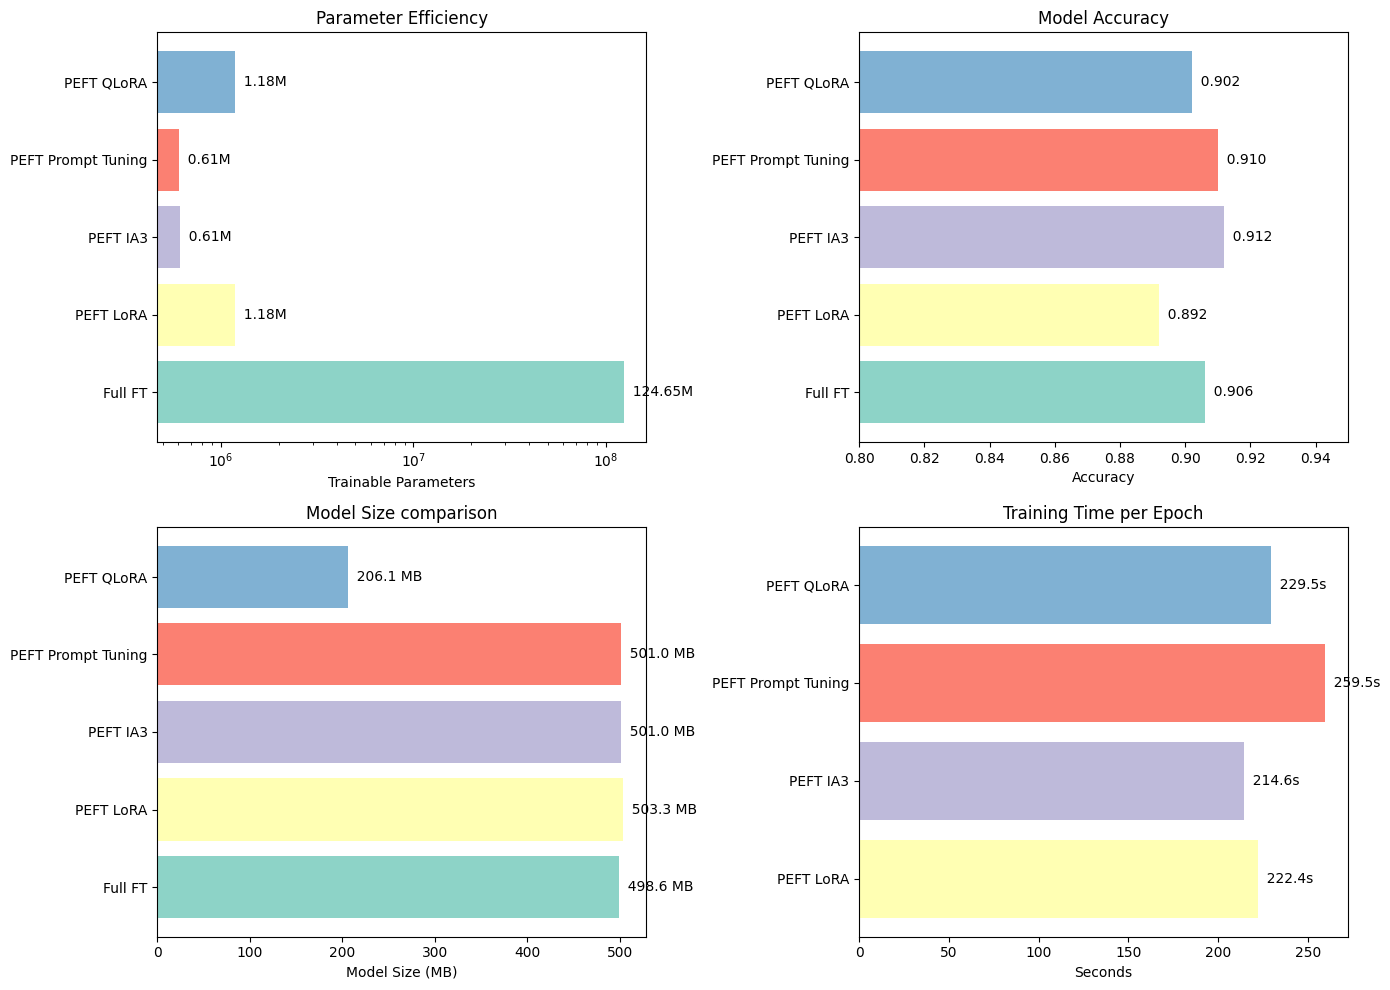

In [35]:
# Visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

# Trainable parameters
methods = df_peft["Method"].tolist()
params = df_peft["Trainable Params"].tolist()
colors = plt.cm.Set3(range(len(methods)))

ax1.barh(methods, params, color=colors)
ax1.set_xlabel("Trainable Parameters")
ax1.set_title("Parameter Efficiency")
ax1.set_xscale("log")
for i, (method, param) in enumerate(zip(methods, params)):
    ax1.text(param, i, f"  {param/1e6:.2f}M", va="center")

# Accuracy
accuracies = df_peft["Accuracy"].tolist()
ax2.barh(methods, accuracies, color=colors)
ax2.set_xlabel("Accuracy")
ax2.set_title("Model Accuracy")
ax2.set_xlim([0.80, 0.95])
for i, (method, acc) in enumerate(zip(methods, accuracies)):
    ax2.text(acc, i, f"  {acc:.3f}", va="center")

# Model Size
model_sizes = df_peft["Model Size (MB)"].tolist()
ax3.barh(methods, model_sizes, color=colors)
ax3.set_xlabel("Model Size (MB)")
ax3.set_title("Model Size comparison")
for i, size in enumerate(model_sizes):
    ax3.text(size, i, f"  {size:.1f} MB", va="center") 

# Time per Epoch
times = df_peft["Time per Epoch"].tolist() 
ax4.barh(methods, times, color=colors)
ax4.set_xlabel("Seconds")
ax4.set_title("Training Time per Epoch")
for i, t in enumerate(times):
    if t and not pd.isna(t):
        ax4.text(t, i, f"  {t:.1f}s", va="center")

plt.tight_layout()
plt.show()